# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python 실행 파일:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("원본 데이터 폴더:", RAW_DIR)
print("보고서 폴더:", REPORT_DIR)


Python 실행 파일: /home/gem/research/프로그램 모음/venvs/llm-data-analysis/bin/python
프로젝트 루트: /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study
원본 데이터 폴더: /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/data/raw
보고서 폴더: /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [2]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [3]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [4]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")


from src.preprocessing import validate_saved_processed_data
input_reload_validation = validate_saved_processed_data(processed_data, PROCESSED_DIR)
display(input_reload_validation)
assert input_reload_validation['status'].eq('PASS').all()
print('저장 후 입력 CSV 재로딩 Gate: PASS')

,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


/home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/data/processed/customers_clean.csv OK
/home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/data/processed/products_clean.csv OK
/home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/data/processed/orders_clean.csv OK
/home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/data/processed/order_items_clean.csv OK


,check,value,status
0,customers.shape,"(150, 6)",PASS
1,customers.columns,6,PASS
2,customers.customer_id_unique_nonnull,0,PASS
3,products.shape,"(100, 4)",PASS
4,products.columns,4,PASS
5,products.product_id_unique_nonnull,0,PASS
6,orders.shape,"(300, 7)",PASS
7,orders.columns,7,PASS
8,orders.order_id_unique_nonnull,0,PASS
9,order_items.shape,"(764, 6)",PASS


저장 후 입력 CSV 재로딩 Gate: PASS


## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [5]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [6]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

line_check = analysis_tables["line_total_check"].iloc[0]
print(
    f"line_total 전체 {int(line_check['row_count'])}행 검증: "
    f"불일치 {int(line_check['mismatch_count'])}건, {line_check['status']}"
)
print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


line_total 전체 764행 검증: 불일치 0건, PASS
병합 / line_total Gate: PASS


## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [7]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-07,5869000,8,733625.0
1,2025-08,15621000,18,867833.0
2,2025-09,10190000,13,783846.0
3,2025-10,25766000,26,991000.0
4,2025-11,8812000,12,734333.0
5,2025-12,11501000,14,821500.0
6,2026-01,17423000,22,791955.0
7,2026-02,9749000,17,573471.0
8,2026-03,13429000,14,959214.0
9,2026-04,17553000,23,763174.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [8]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [9]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [10]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [11]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 133
ch08_preprocessing_comparison.csv True 151
ch08_key_duplicate_checks.csv True 183
ch08_relationship_checks.csv True 202
ch08_merge_checks.csv True 249
ch08_line_total_check.csv True 104
ch08_date_checks.csv True 96
ch08_amount_scope_summary.csv True 137
ch08_total_consistency_check.csv True 215
ch08_project_validation.csv True 385
ch08_category_sales.csv True 246
ch08_monthly_sales.csv True 424
ch08_customer_sales.csv True 3859
ch08_order_status_summary.csv True 97
ch08_interpretation_notes.csv True 1084


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [12]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


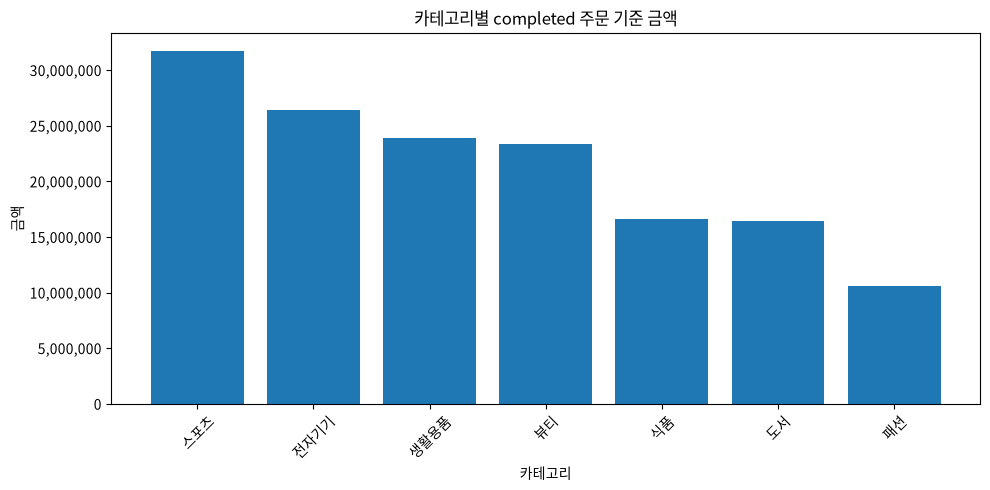

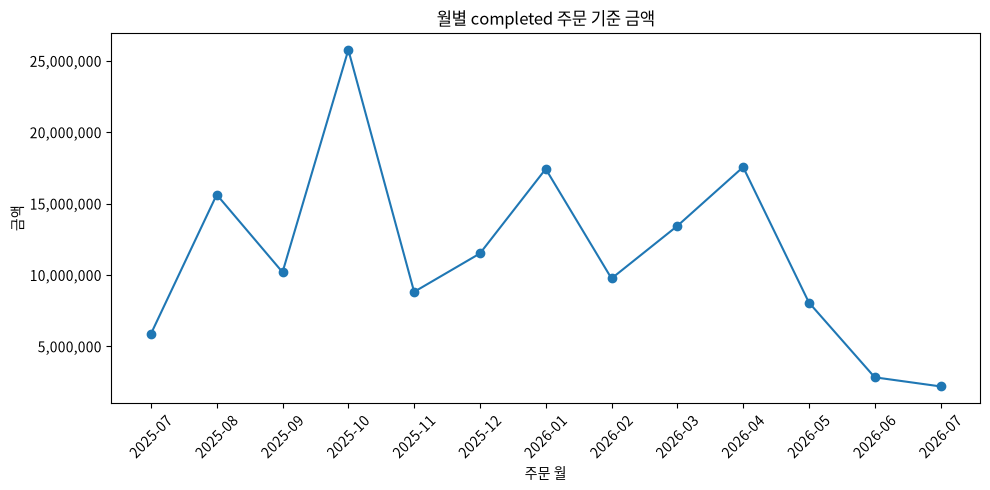

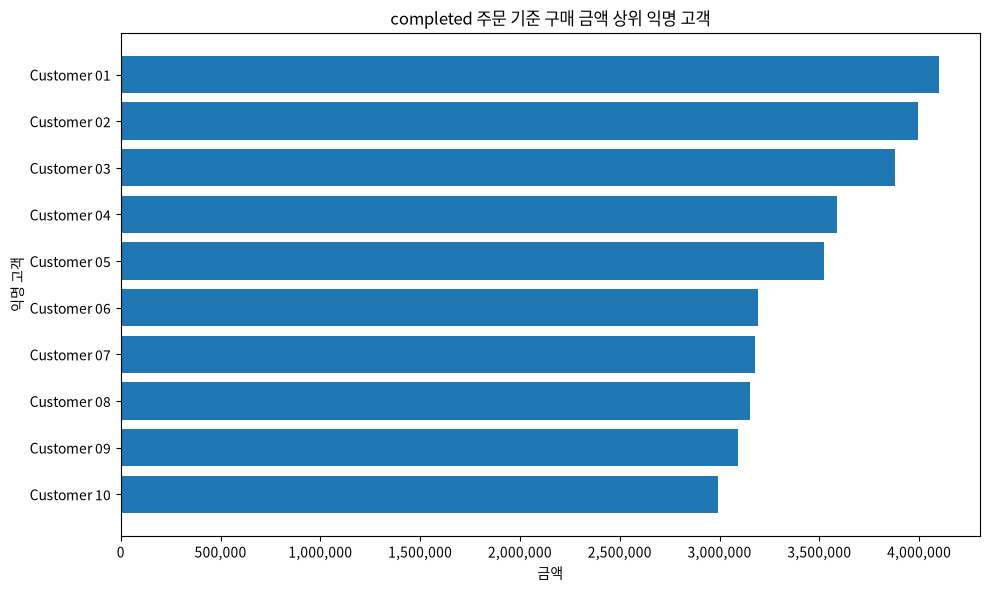

ch08_category_sales.png True 35097
ch08_monthly_sales.png True 85324
ch08_top_customers.png True 60544


In [13]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [14]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150     

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [15]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
project_result["report_path"]


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


PosixPath('/home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_midterm_report.md')

## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [16]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


재실행 명령: /home/gem/research/프로그램 모음/venvs/llm-data-analysis/bin/python scripts/run_midterm_project.py
return code: 0
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_preprocessing_comparison.csv
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_key_duplicate_checks.csv
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_relationship_checks.csv
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_merge_checks.csv
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_line_total_check.csv
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_date_checks.csv
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_amount_scope_summary.csv
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_total_consistency_check.csv
- /home/gem/research/4. 학교 수업/LLM 수업/llm-data-analysis-study/reports/ch08_project_validation.csv
- /home/ge

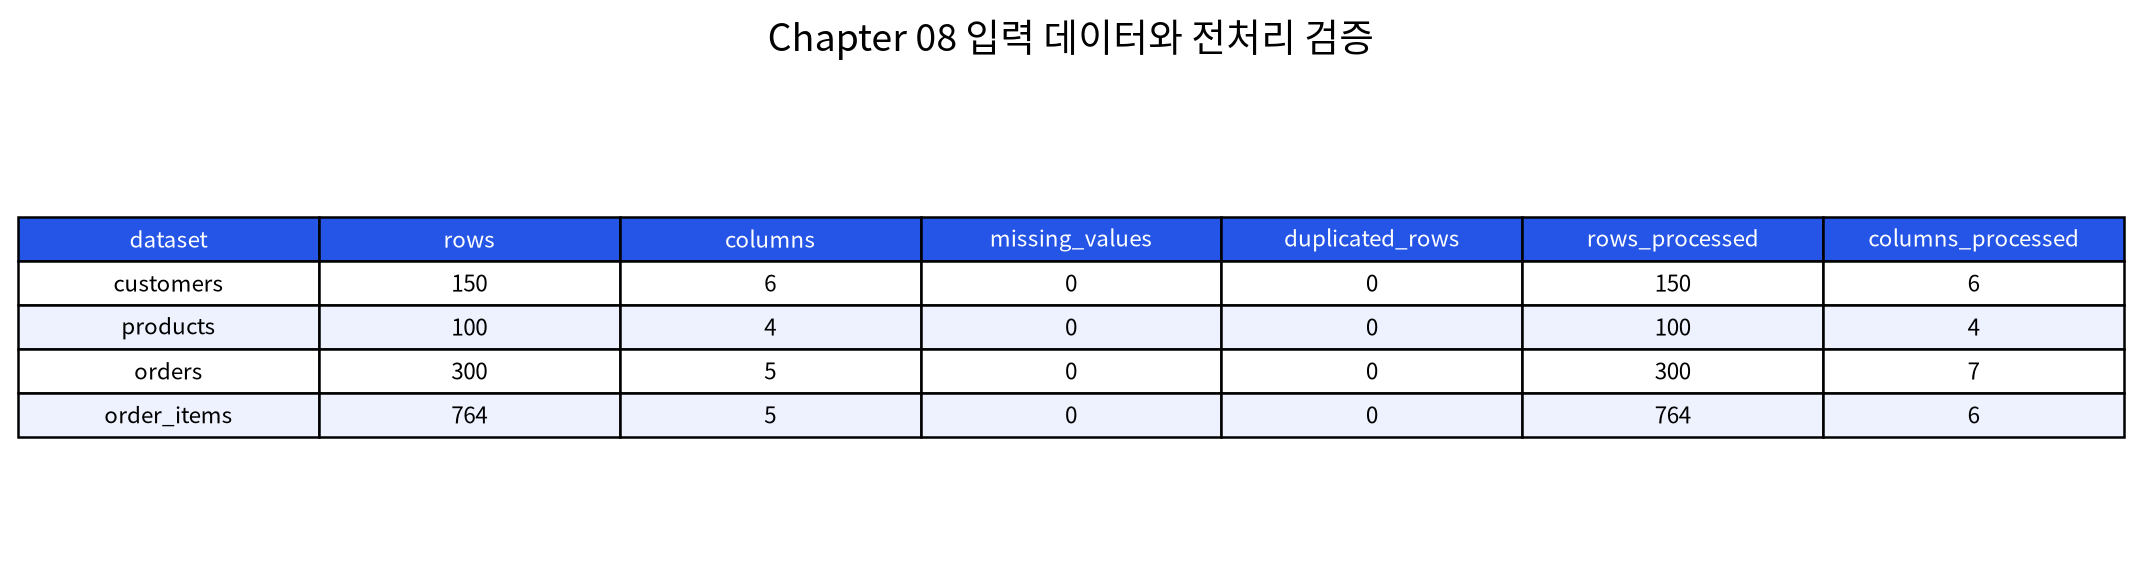

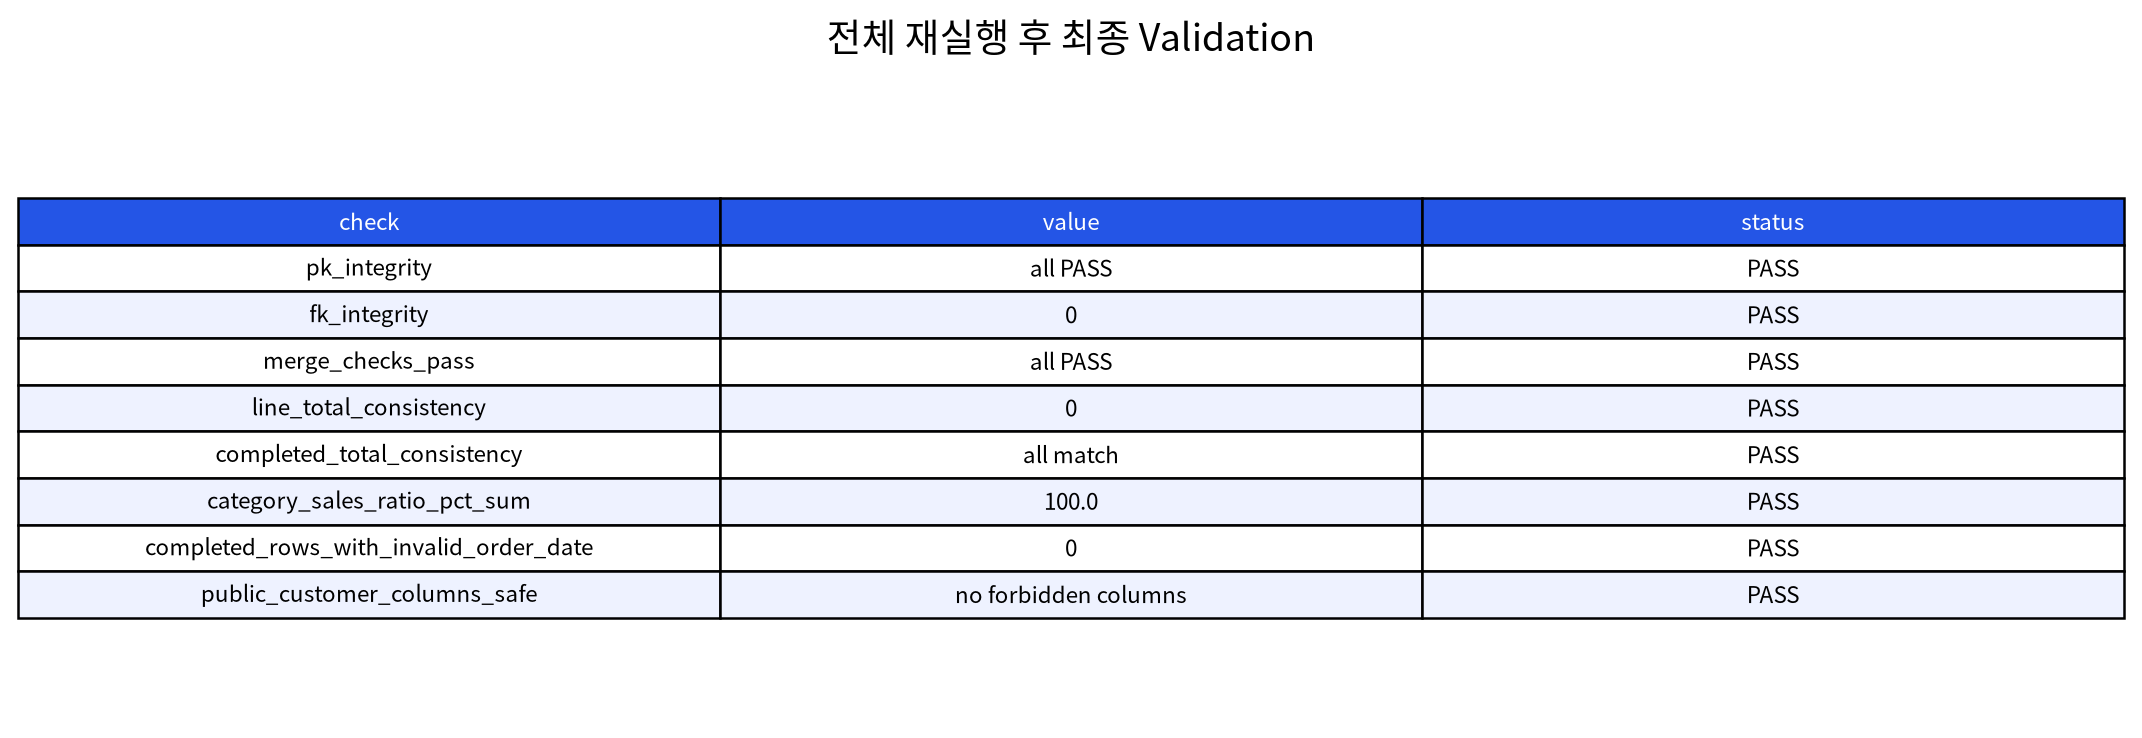

Evidence 생성 및 명령행 재실행: PASS


In [17]:
# 과제 Evidence 생성과 명령행 재실행
from pathlib import Path
from shutil import copy2
import subprocess

import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.visualization import setup_korean_font

EVIDENCE_DIR = PROJECT_ROOT / "chapter08" / "images"
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)
setup_korean_font()


def save_table_image(df, path, title, widths=(12, 3.3)):
    """검증표를 읽을 수 있는 Evidence 이미지로 저장합니다."""
    view = df.copy()
    for column in view.select_dtypes(include="number").columns:
        view[column] = view[column].map(
            lambda value: f"{value:,.0f}" if pd.notna(value) else ""
        )
    fig, ax = plt.subplots(figsize=widths)
    ax.axis("off")
    ax.set_title(title, fontsize=15, pad=18)
    table = ax.table(
        cellText=view.astype(str).values,
        colLabels=view.columns,
        cellLoc="center",
        colLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.45)
    for (row, _), cell in table.get_celld().items():
        if row == 0:
            cell.set_facecolor("#2455E6")
            cell.set_text_props(color="white")
        elif row % 2 == 0:
            cell.set_facecolor("#EEF2FF")
    fig.tight_layout()
    fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
    plt.close(fig)


validation_evidence = dataset_summary.merge(
    preprocessing_comparison[
        ["dataset", "rows_processed", "columns_processed"]
    ],
    on="dataset",
)
save_table_image(
    validation_evidence,
    EVIDENCE_DIR / "step02_data_validation.png",
    "Chapter 08 입력 데이터와 전처리 검증",
)

copy2(
    FIGURE_DIR / "ch08_category_sales.png",
    EVIDENCE_DIR / "graph01.png",
)
copy2(
    FIGURE_DIR / "ch08_monthly_sales.png",
    EVIDENCE_DIR / "graph02.png",
)

# 공지에 제시된 명령을 실제 별도 프로세스로 실행합니다.
reproduce = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "run_midterm_project.py")],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=True,
)
print("재실행 명령:", sys.executable, "scripts/run_midterm_project.py")
print("return code:", reproduce.returncode)
print("\n".join(reproduce.stdout.strip().splitlines()[-24:]))

saved_validation = pd.read_csv(REPORT_DIR / "ch08_project_validation.csv")
assert saved_validation["status"].eq("PASS").all()
save_table_image(
    saved_validation[["check", "value", "status"]],
    EVIDENCE_DIR / "step06_reproduce.png",
    "전체 재실행 후 최종 Validation",
    widths=(12, 4.2),
)

expected_evidence = [
    EVIDENCE_DIR / "step02_data_validation.png",
    EVIDENCE_DIR / "graph01.png",
    EVIDENCE_DIR / "graph02.png",
    EVIDENCE_DIR / "step06_reproduce.png",
]
assert all(path.exists() and path.stat().st_size > 0 for path in expected_evidence)

display(Image(filename=str(EVIDENCE_DIR / "step02_data_validation.png"), width=850))
display(Image(filename=str(EVIDENCE_DIR / "step06_reproduce.png"), width=850))
print("Evidence 생성 및 명령행 재실행: PASS")

# Chapter 08 제출 답안 — 작은 데이터 분석 프로젝트

## 제출 정보

- **이름:** LMS 제출자 정보와 동일
- **GitHub ID:** `chocoemong1`
- **작성일:** 2026-10-27
- **최종 Notebook URL:** <https://github.com/chocoemong1/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb>

> 이 답안의 금액은 모두 실습용 데이터의 `line_total` 합계입니다. 회계상 순매출로 해석하지 않습니다.


## 1. 프로젝트 질문

### 질문 1 — 카테고리별 completed 주문 기준 금액은 어떻게 다른가?

- **분석 대상·범위:** `order_status == "completed"`인 주문 상세
- **데이터·지표:** `orders`, `order_items`, `products`; 카테고리별 `line_total` 합계와 비중
- **완료 기준:** 카테고리 합계가 completed source total과 일치하고 비중 합이 100%이면 완료

### 질문 2 — 월별 completed 주문 기준 금액과 주문 수는 어떻게 변하는가?

- **분석 대상·범위:** 유효한 주문일이 있는 completed 주문
- **데이터·지표:** 월별 `line_total` 합계, 고유 `order_id` 수, 주문당 평균 금액
- **완료 기준:** 날짜 오류가 0건이고 월별 합계가 completed source total과 일치하면 완료

### 질문 3 — completed 주문 기준 구매 금액 상위 고객은 어떤 특징을 보이는가?

- **분석 대상·범위:** completed 주문의 고객별 익명 집계
- **데이터·지표:** 고유 주문 수, 총 구매 금액, 주문당 평균 금액, 도시
- **완료 기준:** 고객 합계가 source total과 일치하고 공개 결과에 원본 ID·직접 식별정보가 없으면 완료

### 공통 계산 기준

- `line_total = quantity × unit_price`를 764개 상세 행에서 다시 검증했습니다.
- 금액성 분석은 `order_status == "completed"`에 한정했습니다.
- 주문 수는 상세 행 수가 아니라 `order_id.nunique()`로 계산했습니다.


## 2. 입력 데이터와 전처리 검증

![입력 데이터 검증](images/step02_data_validation.png)

| 데이터 | 원본 shape | 전처리 shape | 원본 결측 | 원본 전체행 중복 | 변화 |
| --- | ---: | ---: | ---: | ---: | --- |
| customers | 150×6 | 150×6 | 0 | 0 | 행 변화 없음 |
| products | 100×4 | 100×4 | 0 | 0 | 행 변화 없음 |
| orders | 300×5 | 300×7 | 0 | 0 | `order_month`, `order_dayofweek` 추가 |
| order_items | 764×5 | 764×6 | 0 | 0 | 검증된 `line_total` 추가 |

**결과 관찰:** 네 원본 파일은 결측·전체행 중복이 없었고, 전처리 후 행 수가 유지되었습니다. 열 증가는 분석용 파생 변수 추가 때문입니다.

**나의 해석과 판단:** 이번 데이터에서는 삭제로 인한 표본 손실이 없습니다. 다만 전처리 결과를 그대로 신뢰하지 않고 PK/FK와 계산 관계를 별도로 검증했습니다.

**한계와 추가 확인:** 실습용 합성 데이터의 품질이 양호하다는 결과이며, 실제 업무 데이터에서도 같은 결과가 나온다고 일반화할 수 없습니다.


## 3. PK/FK·병합 검증

- **금액 산식:** 전체 764행에서 `line_total = quantity × unit_price`를 비교해 불일치 0건 → **PASS**
- **PK:** `customers.customer_id`, `products.product_id`, `orders.order_id`, `order_items.order_item_id`의 결측·중복이 모두 0건 → **PASS**
- **FK:** 고객·주문·상품 관계의 미매칭이 모두 0건 → **PASS**
- **병합:** 주문·상품은 `many_to_one`, 고객은 `one_to_one`을 사용했습니다.
- **행 수:** 764→764, 474→474, 100→100으로 모두 보존되었고 `left_only`는 0건 → **PASS**

**나의 해석과 판단:** `merge()`가 실행된 사실만으로 정상이라고 보지 않고, 관계·행 수·미매칭을 함께 확인했습니다. 이 검증 덕분에 병합 행 증식이나 집계 누락 없이 후속 분석을 진행할 수 있습니다.


## 4. 핵심 EDA 결과

### 결과 1 — 카테고리별 completed 금액

- **수치:** 스포츠 31,743,000원(21.31%)이 가장 높고, 전자기기 26,400,000원(17.72%)이 뒤를 이었습니다. 상위 두 카테고리의 합계 비중은 39.03%입니다.
- **관찰:** 일곱 카테고리 중 스포츠의 completed 금액 비중이 가장 큽니다.
- **해석·판단:** 현재 데이터에서 스포츠 카테고리의 금액 기여가 상대적으로 큽니다.
- **업무·분석적 의미:** 높은 금액이 수량과 단가 중 무엇에서 비롯되는지 우선 분해해 볼 가치가 있습니다.
- **한계:** 금액만으로 수익성이나 고객 선호의 원인을 판단할 수 없습니다.

### 결과 2 — 월별 completed 금액과 주문 수

- **수치:** 2025년 10월이 25,766,000원·26개 주문으로 금액과 주문 수 모두 가장 높았습니다.
- **관찰:** 월별 금액과 주문 수가 함께 변하지만 두 지표의 크기가 항상 같은 비율로 움직이지는 않습니다.
- **해석·판단:** 월별 차이는 주문 수와 주문당 평균 금액을 함께 보아야 합니다.
- **업무·분석적 의미:** 주문 유입과 객단가를 분리하면 점검할 운영 지표가 더 명확해집니다.
- **한계:** 관찰 기간 양 끝 월은 부분 월이며, 프로모션·재고 자료가 없어 변동 원인을 단정할 수 없습니다.

### 결과 3 — 상위 익명 고객

- **수치:** `Customer 01`은 5개 completed 주문에서 총 4,100,000원, 주문당 평균 820,000원이었습니다. 상위 10명의 합계는 34,694,000원으로 completed 총액의 약 23.29%입니다.
- **관찰:** 상위 고객의 큰 총금액이 반드시 가장 큰 주문당 평균 금액을 뜻하지는 않습니다.
- **해석·판단:** 고객 중요도를 볼 때 총액·빈도·주문당 금액을 함께 확인해야 합니다.
- **업무·분석적 의미:** 반복 구매 고객과 일회성 고액 고객을 구분하는 후속 분석이 유용합니다.
- **한계:** 합성 데이터이며 고객 만족도·이탈 이유·마케팅 반응은 알 수 없습니다.


## 5. Total consistency와 날짜 검증

| 집계 기준 | 금액 | completed source와 일치 |
| --- | ---: | :---: |
| completed source | 148,990,000 | PASS |
| category total | 148,990,000 | PASS |
| monthly total | 148,990,000 | PASS |
| customer total | 148,990,000 | PASS |

- **전체 주문 상세 금액:** 255,610,000원
- **completed 주문 기준 금액:** 148,990,000원
- **제외된 non-completed 금액:** 106,620,000원
- **completed 주문 날짜 오류:** 0건, 영향 금액 0원

**판단:** completed 필터와 날짜 범위가 모든 금액 집계에 일관되게 적용되었습니다. 전체 주문 상세 금액과 completed 금액은 의미가 다르므로 혼용하지 않았습니다.


## 6. 대표 시각화

![카테고리별 completed 금액](images/graph01.png)

![월별 completed 금액](images/graph02.png)

- **선택 이유:** 카테고리 비교에는 막대그래프, 시간 순서가 있는 월별 변화에는 선그래프가 적합합니다.
- **원본 집계 일치:** 두 그래프는 검증된 `ch08_category_sales.csv`, `ch08_monthly_sales.csv`에서 생성했습니다. 각각의 합계는 148,990,000원으로 source total과 일치합니다.
- **직접 관찰:** 스포츠 카테고리의 금액이 가장 높고, 월별 금액은 2025년 10월에 가장 높습니다.
- **해석:** 운영 점검의 우선순위를 정할 출발점이 되지만 원인을 설명하는 결과는 아닙니다.
- **그래프만으로 말할 수 없는 것:** 광고 효과, 고객 선호, 수익성, 계절성 또는 인과관계는 알 수 없습니다.


## 7. 개인정보 검증

- **공개 고객 CSV 컬럼:** `customer_label`, `city`, `order_count`, `total_sales`, `avg_order_value`
- **원본 `customer_id` 포함:** 없음
- **이름·이메일·전화번호·주소 포함:** 없음
- **익명화 방식:** 구매 금액 내림차순의 순위 기반 `Customer 01`, `Customer 02`, …
- **저장 후 재검사:** `reports/ch08_customer_sales.csv`를 다시 읽어 금지 컬럼이 없음을 확인
- **결과:** **PASS**

**나의 판단:** 내부 결합키는 계산 과정에만 사용하고 공개 결과에서는 제거했습니다. 원본 ID 숫자를 라벨에 재사용하지 않아 직접 역추적 가능성을 낮췄습니다.


## 8. 최종 Validation

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | :---: | --- |
| `pk_integrity` | PASS | 네 PK의 결측·중복 0건 |
| `fk_integrity` | PASS | 세 FK 미매칭 0건 |
| `merge_checks_pass` | PASS | 행 수 보존, 미매칭 0건 |
| `line_total_consistency` | PASS | 764행 불일치 0건 |
| `completed_total_consistency` | PASS | 네 총합 모두 148,990,000원 |
| `category_sales_ratio_pct_sum` | PASS | 비중 합계 100.0% |
| `completed_rows_with_invalid_order_date` | PASS | 오류 0건·영향 0원 |
| `public_customer_columns_safe` | PASS | 저장 CSV에 금지 컬럼 없음 |

**FAIL 수정 내용:** 분석 단계의 FAIL은 없었습니다. 공식 스크립트가 개인 저장소에서 `src`를 찾지 못한 실행 경로 문제는 저장소 루트를 명시하도록 수정한 후 같은 명령으로 재실행했습니다.


## 9. LLM 활용 기록

- **사용 여부:** 사용
- **사용 목적:** 요구사항 체크, 검증 코드와 분석 문장 검토, 과대 해석 점검
- **Safe Context:** 스키마, 익명 집계표, PK/FK·병합·total consistency·Validation 결과만 사용했으며 고객 원본 행과 이름은 제공하지 않았습니다.
- **Prompt 요약:** “completed 범위를 일관되게 사용했는지, 같은 의미의 총합이 일치하는지, 공개 고객 결과가 안전한지 검토해 달라.”
- **LLM 제안:** PK 결측·중복, FK 미매칭, 병합 행 수, `line_total`, 날짜, 총합, 저장 CSV 개인정보를 각각 Gate로 확인
- **반영/수정:** 검증 항목은 반영했습니다. 원인으로 단정하는 표현은 관찰·추가 확인으로 수정했습니다.
- **검증 근거:** 실제 원본에서 전체 파이프라인을 실행하고, 저장된 CSV를 다시 읽어 모든 Validation이 PASS인지 확인했습니다. LLM이 생성한 숫자를 사용하지 않았습니다.


## 10. 프로젝트 재현 확인

![전체 재실행 결과](images/step06_reproduce.png)

- **실행 명령:** `python scripts/run_midterm_project.py`
- **실행 여부:** 별도 프로세스로 처음부터 재실행 완료
- **결과:** `reports/ch08_project_validation.csv`의 8개 항목 모두 PASS
- **Notebook과 핵심 수치:** completed·category·monthly·customer 총액이 모두 148,990,000원으로 일치
- **Evidence:** 입력 검증 1개, 대표 그래프 2개, 재실행 Validation 1개 생성 확인

**나의 해석과 판단:** 전체 재실행은 Notebook 메모리에 우연히 남은 변수에 의존하지 않고, 원본에서 같은 결과를 다시 만들 수 있는지 확인하는 최소 조건입니다.


## 11. 최종 프로젝트 요약

### 핵심 인사이트 3개

1. 스포츠 카테고리가 completed 금액 31,743,000원·21.31%로 가장 컸지만, 금액만으로 수익성이나 선호 원인을 판단할 수는 없습니다.
2. 2025년 10월은 completed 금액 25,766,000원과 주문 26건으로 가장 높았습니다. 원인을 말하려면 프로모션·재고 등 추가 데이터가 필요합니다.
3. 상위 익명 고객 10명의 completed 금액은 전체의 약 23.29%였습니다. 총액뿐 아니라 주문 빈도와 주문당 금액을 함께 보아야 합니다.

### 가장 중요한 업무·분석적 의미

같은 completed 범위를 사용하고 총합을 교차 검증하면, 카테고리·월·고객이라는 서로 다른 관점의 결과를 모순 없이 비교할 수 있습니다.

### 현재 분석의 한계

- 실습용 합성 데이터이므로 실제 시장으로 일반화할 수 없습니다.
- 금액은 `line_total` 합계이며 회계상 순매출이나 이익이 아닙니다.
- 관찰 기간의 양 끝 월은 부분 월입니다.
- 프로모션·재고·원가·고객 행동 원인 데이터가 없습니다.

### 다음 분석 제안

1. 카테고리 금액을 판매 수량과 평균 판매 단가로 분해합니다.
2. 월별 completed 주문 수와 주문당 평균 금액을 함께 비교합니다.
3. 익명 고객의 최근 구매일·빈도·금액을 결합해 반복 구매와 일회성 고액 구매를 구분합니다.


In [18]:
# 제출 직전 최종 Gate
final_validation = pd.read_csv(REPORT_DIR / "ch08_project_validation.csv")
final_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")
final_total = pd.read_csv(REPORT_DIR / "ch08_total_consistency_check.csv")
input_reload = pd.read_csv(REPORT_DIR / "ch08_input_reload_validation.csv")
output_reload = pd.read_csv(REPORT_DIR / "ch08_output_reload_validation.csv")
file_validation = pd.read_csv(REPORT_DIR / "ch08_file_validation.csv")

for gate in [final_validation, final_total, input_reload, output_reload, file_validation]:
    assert gate["status"].eq("PASS").all()
assert not FORBIDDEN_CUSTOMER_COLUMNS.intersection(final_customer.columns)
assert all(path.exists() and path.stat().st_size > 0 for path in expected_evidence)

display(input_reload)
display(output_reload)
display(file_validation)
print("FINAL SUBMISSION GATE: PASS")
print("제출 URL:")
print("https://github.com/chocoemong1/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb")

,check,value,status
0,customers.shape,"(150, 6)",PASS
1,customers.columns,6,PASS
2,customers.customer_id_unique_nonnull,0,PASS
3,products.shape,"(100, 4)",PASS
4,products.columns,4,PASS
5,products.product_id_unique_nonnull,0,PASS
6,orders.shape,"(300, 7)",PASS
7,orders.columns,7,PASS
8,orders.order_id_unique_nonnull,0,PASS
9,order_items.shape,"(764, 6)",PASS


,artifact,value,exists,shape_match,columns_match,content_match,status
0,ch08_dataset_summary.csv,"shape=(4, 5)",True,True,True,True,PASS
1,ch08_preprocessing_comparison.csv,"shape=(4, 5)",True,True,True,True,PASS
2,ch08_key_duplicate_checks.csv,"shape=(4, 6)",True,True,True,True,PASS
3,ch08_relationship_checks.csv,"shape=(3, 3)",True,True,True,True,PASS
4,ch08_merge_checks.csv,"shape=(3, 7)",True,True,True,True,PASS
5,ch08_line_total_check.csv,"shape=(1, 5)",True,True,True,True,PASS
6,ch08_date_checks.csv,"shape=(1, 4)",True,True,True,True,PASS
7,ch08_amount_scope_summary.csv,"shape=(3, 3)",True,True,True,True,PASS
8,ch08_total_consistency_check.csv,"shape=(4, 5)",True,True,True,True,PASS
9,ch08_project_validation.csv,"shape=(8, 4)",True,True,True,True,PASS


,artifact,value,exists,status
0,ch08_category_sales.png,bytes=35097,True,PASS
1,ch08_monthly_sales.png,bytes=85324,True,PASS
2,ch08_top_customers.png,bytes=60544,True,PASS
3,ch08_midterm_report.md,bytes=9179,True,PASS


FINAL SUBMISSION GATE: PASS
제출 URL:
https://github.com/chocoemong1/llm-data-analysis-study/blob/main/chapter08/chapter08.ipynb


## 최종 체크

- [x] 질문과 지표가 연결됩니다.
- [x] 원본 데이터에서 다시 시작했습니다.
- [x] PK/FK·병합 검증 근거가 있습니다.
- [x] `line_total = quantity × unit_price`를 확인했습니다.
- [x] 금액성 분석은 completed 범위를 사용했습니다.
- [x] category/month/customer 총합이 source total과 일치합니다.
- [x] 날짜 오류를 확인했습니다.
- [x] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [x] 대표 그래프와 원본 집계값을 비교했습니다.
- [x] 원인을 과대 해석하지 않았습니다.
- [x] 입력 CSV와 저장 결과표를 다시 열어 구조·내용이 모두 PASS입니다.
- [x] 최종 Validation이 모두 PASS입니다.
- [x] 전체 프로젝트를 별도 프로세스로 재실행했습니다.
- [x] 한계와 다음 분석을 작성했습니다.
- [x] 최종 Notebook URL을 준비했습니다.


## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```
